# Preliminary Analysis

From our work in `get_reactor_data.ipynb`, we learned two things:

Over 26 years, refueling outages account for about 81% of all zero-power days. Unplanned outages are more frequent but short. By count, unplanned outages are actually the most common (44%), but they're short (12.8% of days).

In this notebook we use the cleaned reactor data from `get_reactor_data.ipynb` to forecast each reactor's average quarterly power output. All the methods here are **univariate**: each forecast uses only that reactor's past power values, with no other features.

We compare four methods, going from simple baselines to more flexible models, and explain each one as we go:

1. **Seasonal naive**: repeat the most recent refueling cycle.
2. **Seasonal average**: average the same point over the last few refueling cycles.
3. **Holt-Winters (triple exponential smoothing)**: a level and a seasonal pattern that update as new data comes in.
4. **Seasonal ARIMA (SARIMA)**: models each quarter's power from past quarters and from the same point in previous cycles.

Here the "season" is the reactor's **refueling cycle** (18 or 24 months), not the calendar year.


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Our cleaned reactor data lives here
outdir = Path("/Users/vassu/Desktop/Erdos_DataScience/NuclearReliability/reactor_data/cleaned_data/")

# load the data. We need to pass on the parse_dates option so that we can perform operations on the date column
# By default the date column will be treated as a string (because of the dashes)

all_years = []

for year in range(2000, 2026):

    df = pd.read_csv(outdir/f"CleanedData_{year}.csv", sep="\t", parse_dates=["date"])
    all_years.append(df)

df = pd.concat(all_years, ignore_index=True)

# Using the dates Column to define a quarter period
df["quarter_period"] = df["date"].dt.to_period("Q")
df.head()

,date,Region,Unit,Power,Down,Reason,quarter_period
0,2000-01-01,Region 4,Arkansas Nuclear One 1,80,NaN,Y2K TRANSITION PLANNED POWER,2000Q1
1,2000-01-02,Region 4,Arkansas Nuclear One 1,100,NaN,NaN,2000Q1
2,2000-01-03,Region 4,Arkansas Nuclear One 1,100,NaN,NaN,2000Q1
3,2000-01-04,Region 4,Arkansas Nuclear One 1,100,NaN,NaN,2000Q1
4,2000-01-05,Region 4,Arkansas Nuclear One 1,100,NaN,NaN,2000Q1


In [2]:
# Now we want the average power over each quarter

# groupby turns Unit, Region and quarter_period into the index, with the mean as the only column.
# reset_index moves them back into regular columns.

quarter_df = df.groupby(["Unit", "Region", "quarter_period"])["Power"].agg(["mean"]).reset_index()
quarter_df = quarter_df.rename(columns={"mean": "average_power"})

# Store the start date of each quarter so we can match it to the outages table and count the days since the last refuel for later modeling.

quarter_df["quarter_start"] = quarter_df["quarter_period"].dt.start_time
quarter_df.head()

,Unit,Region,quarter_period,average_power,quarter_start
0,Arkansas Nuclear One 1,Region 4,2000Q1,44.252747,2000-01-01
1,Arkansas Nuclear One 1,Region 4,2000Q2,98.670330,2000-04-01
2,Arkansas Nuclear One 1,Region 4,2000Q3,100.000000,2000-07-01
3,Arkansas Nuclear One 1,Region 4,2000Q4,100.000000,2000-10-01
4,Arkansas Nuclear One 1,Region 4,2001Q1,81.100000,2001-01-01


## Quarterly power over time

Before choosing a forecasting method, let's look at what the series look like. Below we plot the quarterly average power for each reactor in Region 1 from 2000 to 2025.

Things to look for:
- **Trend:** does power drift up or down over the years?
- **Repeating patterns:** are there regular drops, and how far apart are they?
- **One-off events:** are there drops that don't follow any pattern?

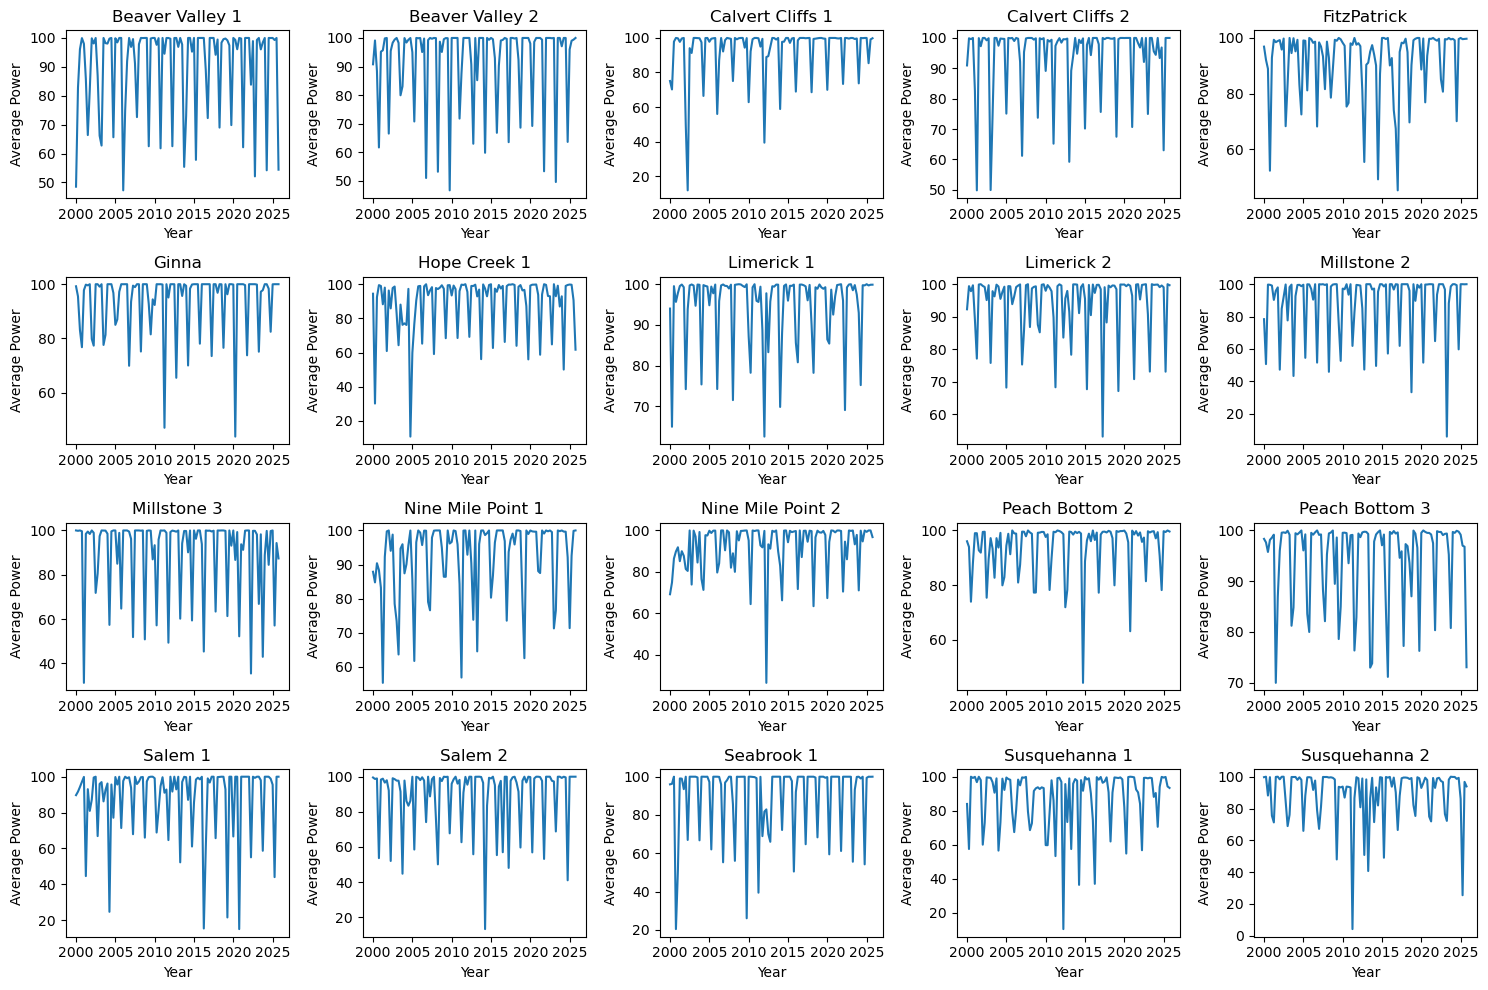

In [3]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import math

region = "Region 1"
regional_df = quarter_df[ quarter_df["Region"] == region ]
n_reactors = regional_df["Unit"].nunique()
reactors = regional_df["Unit"].unique()

n_rows = 4
n_columns = math.ceil(n_reactors/n_rows)

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15,10))
axes = axes.flatten()

for i in range(n_reactors):
    axes[i].plot(regional_df[regional_df["Unit"] == reactors[i]]["quarter_start"], regional_df[regional_df["Unit"] == reactors[i]]["average_power"])
    axes[i].set_xlabel("Year")
    axes[i].set_ylabel("Average Power")
    axes[i].set_title(f'{reactors[i]}')
    axes[i].xaxis.set_major_locator(mdates.YearLocator(5))
plt.tight_layout()
plt.show()

Most reactors run close to 100% power, with sharp drops at regular intervals. These are the refueling outages. There is no long-term trend, but the series is clearly seasonal, and the season length differs between reactors. Next we measure the refueling cycle length for each reactor.

In [4]:
outages_df = pd.read_csv(outdir/"outages_data.csv", sep="\t", parse_dates=["Start_Date", "End_Date"])

refueling_df = outages_df[ outages_df["outage_reason"] == "refueling outage" ].sort_values(["Unit", "Start_Date"]).reset_index(drop=True)

for unit, unit_df in refueling_df.groupby("Unit"):

    refueling_df.loc[refueling_df["Unit"] == unit, "months_since_last_refuel"] = (unit_df["Start_Date"] - unit_df["End_Date"].shift(1)).dt.days/30

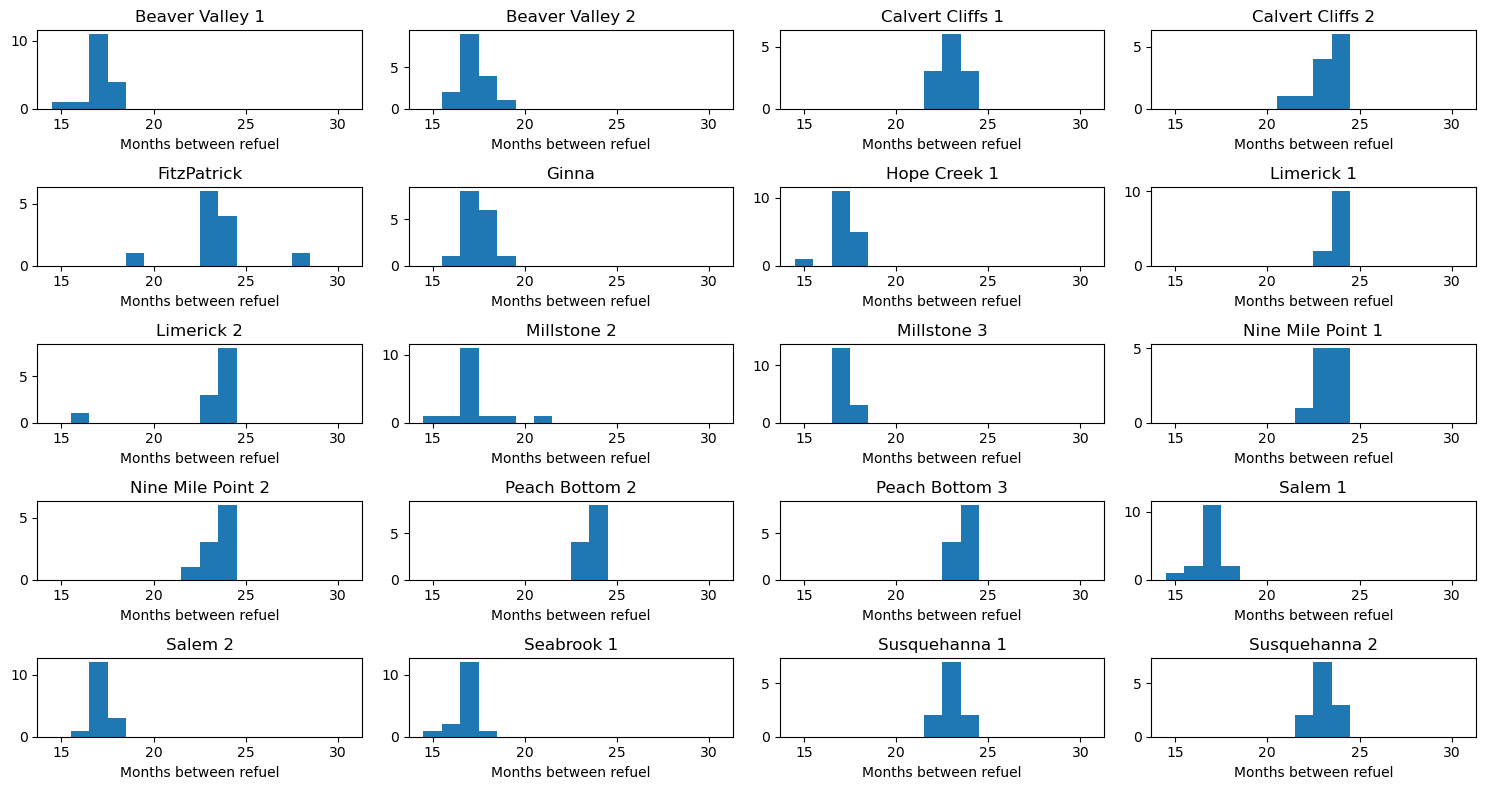

In [5]:
region = "Region 1"
regional_df = refueling_df[ refueling_df["Region"] == region ]
reactors = regional_df["Unit"].unique()

n_rows = 5
n_columns = math.ceil(len(reactors)/n_rows)

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15,8))
axes = axes.flatten()

for i in range(len(reactors)):

    axes[i].hist(regional_df[ regional_df["Unit"] == reactors[i]]["months_since_last_refuel"], bins=16, range=(14.5, 30.5))
    axes[i].set_xlabel("Months between refuel")
    axes[i].set_title(f'{reactors[i]}')

plt.tight_layout()
plt.show()

Most reactors fall clearly into one of two groups: an **18-month** or a **24-month** refueling cycle. Many reactors, however, are a mix of the two, either because they switched cycle length at some point (for example Oconee 1–3 and Robinson 2) or because some intervals were stretched by long forced outages. This makes it hard to assign one cycle length to a reactor's whole history.

Since our forecasts look forward, what matters most is the cycle a reactor is on **now**. So we define each reactor's cycle length from its most recent behaviour: the **median of its last 3 refueling intervals** in the training period. The median keeps one unusual interval from distorting the result. We then round to the nearest cycle length in quarters: **6 quarters** (18 months) or **8 quarters** (24 months).

*However, we have to be careful here: the cycle length must come from the **training period only**. If we used the most recent refuels in the full data, many of them would fall in the test period, and the forecasts would be using information from the future they are trying to predict.*


In [6]:
training_period = pd.Timestamp("2021-01-01")

# Watts Bar 2 began commercial operation in late 2016; earlier quarters are the commissioning ramp, not normal operation
# Look at "get_reactor_data.ipynb" notebook

commissioning = (quarter_df["Unit"] == "Watts Bar 2") & (quarter_df["quarter_start"] < "2016-10-01")
quarter_df = quarter_df[~commissioning]

X_train = quarter_df[ quarter_df["quarter_start"] < training_period][["Unit", "Region", "quarter_start", "average_power"]]

X_test = quarter_df[ quarter_df["quarter_start"] >= training_period][["Unit", "Region", "quarter_start", "average_power"]]

# Let's now define the cycle lengths for each reactor. Since the cycle length has changed for some reactors it makes sense to take the median of the last few refuels in the past

# refueling_df already has this information but we only use the training data period

# We define this as a function because cross-validation uses several cutoff dates,
# and each fold must use the cycle length known at its own cutoff, not the one from the full training period.

def get_cycle_quarters(cutoff, n_recent=3):

    past = refueling_df[(refueling_df["End_Date"] < cutoff) & (refueling_df["months_since_last_refuel"] >= 12)]
    months = past.groupby("Unit")["months_since_last_refuel"].apply(lambda s: s.tail(n_recent).median())
    return {unit: 6 if m < 21 else 8 for unit, m in months.items()}

# This is for the final training/testing
cycle_quarters = get_cycle_quarters(training_period)

## Baseline forecasts

Our quarterly power has no long-term trend but repeats with the refueling cycle, so it falls into the "seasonality, no trend" category. This gives two natural baselines. Let $T$ be the reactor's cycle length in quarters (6 or 8), $n$ the last training quarter, and $h = 1, 2, \dots$ the number of quarters ahead.

**Seasonal naive:** repeat the last observed cycle. Each future quarter gets the value from the same point in the most recent training cycle:

$$
\hat{y}_{n+h} = y_{n - T + 1 + ((h-1) \bmod T)}
$$

It is simple and follows recent changes in cycle length, but it relies on a single cycle, so one unusual cycle (for example a long forced outage) carries straight into every forecast.

**Seasonal average over the last $k$ cycles:** average the same point over the last $k$ training cycles, then repeat that pattern:

$$
\hat{y}_{n+h} = \frac{1}{k} \sum_{j=0}^{k-1} y_{n - jT - T + 1 + ((h-1) \bmod T)}
$$

With $k = 1$ this is the seasonal naive forecast. With $k$ covering all past cycles, it is the classic seasonal average. Averaging over all cycles is a poor choice here: reactors that changed cycle length would mix cycles of different lengths, and older outages would be lined up with the wrong quarters. A small $k$ smooths out one-off cycles while still following recent changes. We choose $k$ using cross-validation on the training data.


In [7]:
from sklearn.metrics import root_mean_squared_error as rmse
from sklearn.metrics import mean_absolute_error as mae

cutoffs = pd.to_datetime(["2013-01-01", "2015-01-01", "2017-01-01" , "2020-01-01"])
fold_cycles = {cut_off: get_cycle_quarters(cut_off) for cut_off in cutoffs}
cycles_considered = [2, 3, 4, 5]
scores=[]

for unit, unit_df in X_train.groupby("Unit"):

    for cut_off in cutoffs:

        if unit not in fold_cycles[cut_off]:
            continue
        
        length = fold_cycles[cut_off][unit]

        training_data = unit_df[(unit_df["quarter_start"] < cut_off)]["average_power"].to_numpy()

        # for an apples to apples comparison we should forecast over the same horizon for all these cut offs
        test_data = unit_df[(unit_df["quarter_start"] >= cut_off)]["average_power"].to_numpy()[:20]
        
        # How many full cycles there are in the training data
        n_cycles = len(training_data) // length
        
        if n_cycles < max(cycles_considered) or len(test_data) == 0:
            continue
        
        for cycle in cycles_considered:

            all_cycles = training_data[-cycle*length:].reshape(cycle, length)
            cycle_mean = np.mean(all_cycles, axis=0)

            h = np.arange(len(test_data))
            scores.append({"Unit": unit, "Cutoff": cut_off, "cycles": cycle, "RMSE": rmse(test_data, cycle_mean[h%length]), "MAE": mae(test_data, cycle_mean[h%length]) })


scores = pd.DataFrame(scores)
scores.groupby(["cycles"])[["RMSE", "MAE"]].agg(["mean"])

,RMSE,MAE
,mean,mean
cycles,,
2,11.038065,7.361926
3,10.732164,7.235064
4,10.660831,7.310425
5,10.696849,7.431442


The errors are very similar for all values of cycles: the mean MAE differs by only about 0.1 between the best and worst choice. So the seasonal average is not very sensitive to how many cycles we average over. We use **cycles = 4**, which gives the lowest mean MAE and an RMSE essentially tied with cycles = 5.


In [8]:
cycles_considered = 4

for unit, unit_df in X_test.groupby("Unit"):

    if unit not in cycle_quarters:
        continue

    length = cycle_quarters[unit]

    # Seasonal Naive Forecast

    previous_quarters_data = X_train[ X_train["Unit"] == unit ]["average_power"].tail(length).to_numpy()

    h = np.arange(len(unit_df))
    X_test.loc[ unit_df.index, "seasonal_naive" ] = previous_quarters_data[h%length]

    n_cycles = len(X_train[X_train["Unit"] == unit]) // length
    training_data = X_train[X_train["Unit"] == unit]["average_power"].to_numpy()
    
    k = min(n_cycles, cycles_considered)
    all_cycles = training_data[-k*length:].reshape(k, length)
    cycle_mean = np.mean(all_cycles, axis=0)

    # Seasonal Average Forecast with last 4 cycles averaged

    X_test.loc[unit_df.index, "seasonal_average"] = cycle_mean[h%length]


## Holt-Winters (triple exponential smoothing)

The seasonal baselines give every past cycle in their window the **same weight**. Exponential smoothing instead gives **more weight to recent data**, with older observations fading out gradually.

The full Holt-Winters method tracks three components (hence "triple"): a **level**, a **trend** and a **seasonal pattern**. Our series has no trend, so we keep only the level and the additive seasonal pattern. With $T$ the cycle length in quarters:

$$
\begin{aligned}
\text{Level:} \quad & \ell_t = \alpha\,(y_t - s_{t-T}) + (1-\alpha)\,\ell_{t-1} \\
\text{Season:} \quad & s_t = \gamma\,(y_t - \ell_{t-1}) + (1-\gamma)\,s_{t-T} \\
\text{Forecast:} \quad & \hat{y}_{n+h} = \ell_n + s_{n+h-T\lceil h/T \rceil}
\end{aligned}
$$

- The **level** $\ell_t$ is the reactor's typical power once the seasonal effect is removed.
- The **seasonal term** $s_t$ is how far each point in the cycle sits above or below the level.
- The forecast is the latest level plus the latest estimate of the seasonal term for that point in the cycle, repeated every $T$ quarters.

The two smoothing parameters, between 0 and 1, control how quickly each component adapts:
- **$\alpha$** (level): close to 1 means the level follows the latest quarters closely; close to 0 means it changes slowly.
- **$\gamma$** (season): close to 1 means the seasonal pattern is driven by the most recent cycle (like seasonal naive); close to 0 means it is averaged over many cycles (like the seasonal average).

So Holt-Winters sits between our two baselines, and the data decide where. We choose $\alpha$ and $\gamma$ by a grid search with the same cross-validation folds as before, using the cycle length known at each cutoff.


In [9]:
# In order to test against every combination of alphas and gammas we will use the "itertools" library
# We will use the same cutoffs as defined above

import itertools as itr
from statsmodels.tsa.api import ExponentialSmoothing

alphas = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
gammas = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results= {}

for unit, unit_df in X_train.groupby("Unit"):

    best_score = np.inf

    for alpha, gamma in itr.product(alphas, gammas):

        fold_scores = []

        for cut_off in cutoffs:

            if unit not in fold_cycles[cut_off]:
                continue

            length = fold_cycles[cut_off][unit]
        
            # If you give a pandas dataframe the forecast will come back as a series and since we are selecting particular rows from the dataframe, the index will be all around and that would create a problem in forecast.
    
            # for example, the input is the training data and say it has 100 quarters (as a dataframe, you would need to do reset_index(drop=True) so the indices are continuous) so the prediction will come out as a series starting from index 101
    
            train_set = unit_df[ unit_df["quarter_start"] < cut_off ]["average_power"].to_numpy()
            val_set = unit_df[ unit_df["quarter_start"] >= cut_off ]["average_power"].to_numpy()[:20]
    
            # For initilization the model needs at least two full seasonal cycles apparently
            # so one cycle for initilization and one for the update

            # If there is nothing in the validation set that is also useless
    
            if len(train_set) < 2*length or len(val_set) == 0:
                continue

            model = ExponentialSmoothing( train_set, seasonal='add', seasonal_periods=length).fit(smoothing_level=alpha, smoothing_seasonal=gamma, optimized=False)

            fold_scores.append(mae(val_set, model.forecast(len(val_set))))

        if len(fold_scores) == 0:
            continue

        score = np.mean(fold_scores)

        if score < best_score:
            best_score = score
            results[unit] = { "alpha": alpha, "gamma": gamma, "score": score } 

In [10]:
for unit, unit_df in X_test.groupby("Unit"):

    if unit not in cycle_quarters:
        continue

    length = cycle_quarters[unit]

    if unit in results:
        alpha = results[unit]["alpha"]
        gamma = results[unit]["gamma"]
    else:
        alpha, gamma = 0.1, 0.3

    # Example of using a dataframe as an input in this case
    holt_winter = ExponentialSmoothing(X_train[X_train["Unit"] == unit]["average_power"].reset_index(drop=True), seasonal='add', seasonal_periods=length).fit(smoothing_level=alpha, smoothing_trend=0.1, smoothing_seasonal=gamma, optimized=False)

    # In this line this mismatch of indices since the right hand side is a series will create a problem
    # The easiest way is to pass the input as a numpy array avoiding all these problems.

    X_test.loc[unit_df.index, "holt_winter"] = holt_winter.forecast(len(unit_df)).to_numpy()
    X_train.loc[X_train[X_train["Unit"] == unit].index, "holt_winter_fit"] = holt_winter.fittedvalues.to_numpy()

## Seasonal ARIMA: looking at the autocorrelations

Holt-Winters and the baselines assume a fixed shape for the forecast. ARIMA models instead **learn from the data** how each quarter depends on earlier ones. To choose sensible model orders, we first look at two diagnostic plots:

- **Autocorrelation function (ACF):** the correlation between the series and itself shifted by $k$ quarters. A large value at lag $k$ means a quarter tells us a lot about the quarter $k$ steps later.
- **Partial autocorrelation function (PACF):** the same correlation, but after removing the effect of all shorter lags. It shows which lags carry **new** information.

What to look for:
- **Peaks at multiples of the cycle length** (lags 6, 12, 18, … or 8, 16, 24, …) confirm the refueling seasonality and suggest seasonal terms.
- **Spikes at the first few lags** show short-term memory, for example a strong quarter tending to follow another strong one.
- As a rule of thumb, a PACF that cuts off after a few lags points to **autoregressive (AR)** terms, and an ACF that cuts off points to **moving-average (MA)** terms.

The shaded band marks the 95% significance level: spikes inside it are indistinguishable from noise.

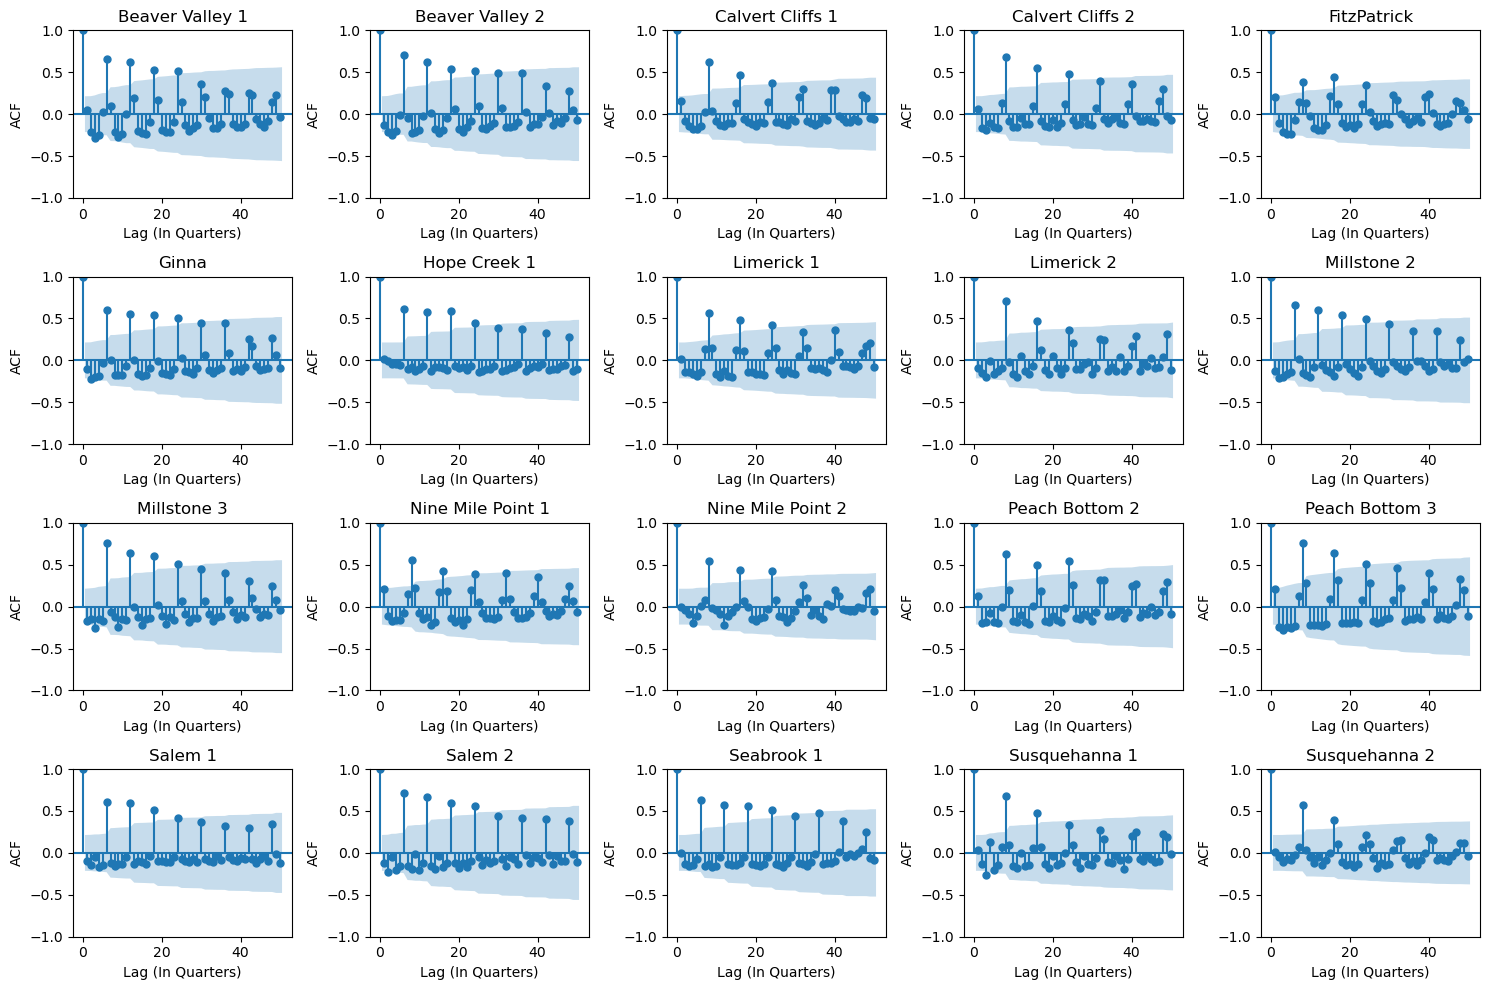

In [11]:
import statsmodels.api as sm

region = "Region 1"

regional_df = X_train[ X_train["Region"] == region ]
reactors = regional_df["Unit"].unique()

n_rows = 4
n_columns = math.ceil(len(reactors)/n_rows)

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 10))
axes = axes.flatten()

for i in range(len(reactors)):  

    sm.graphics.tsa.plot_acf(regional_df[ regional_df["Unit"] == reactors[i] ]["average_power"].reset_index(drop=True), lags=50, ax=axes[i])

    axes[i].set_xlabel("Lag (In Quarters)")
    axes[i].set_ylabel("ACF")
    axes[i].set_title(f'{reactors[i]}')

plt.tight_layout()
plt.show()

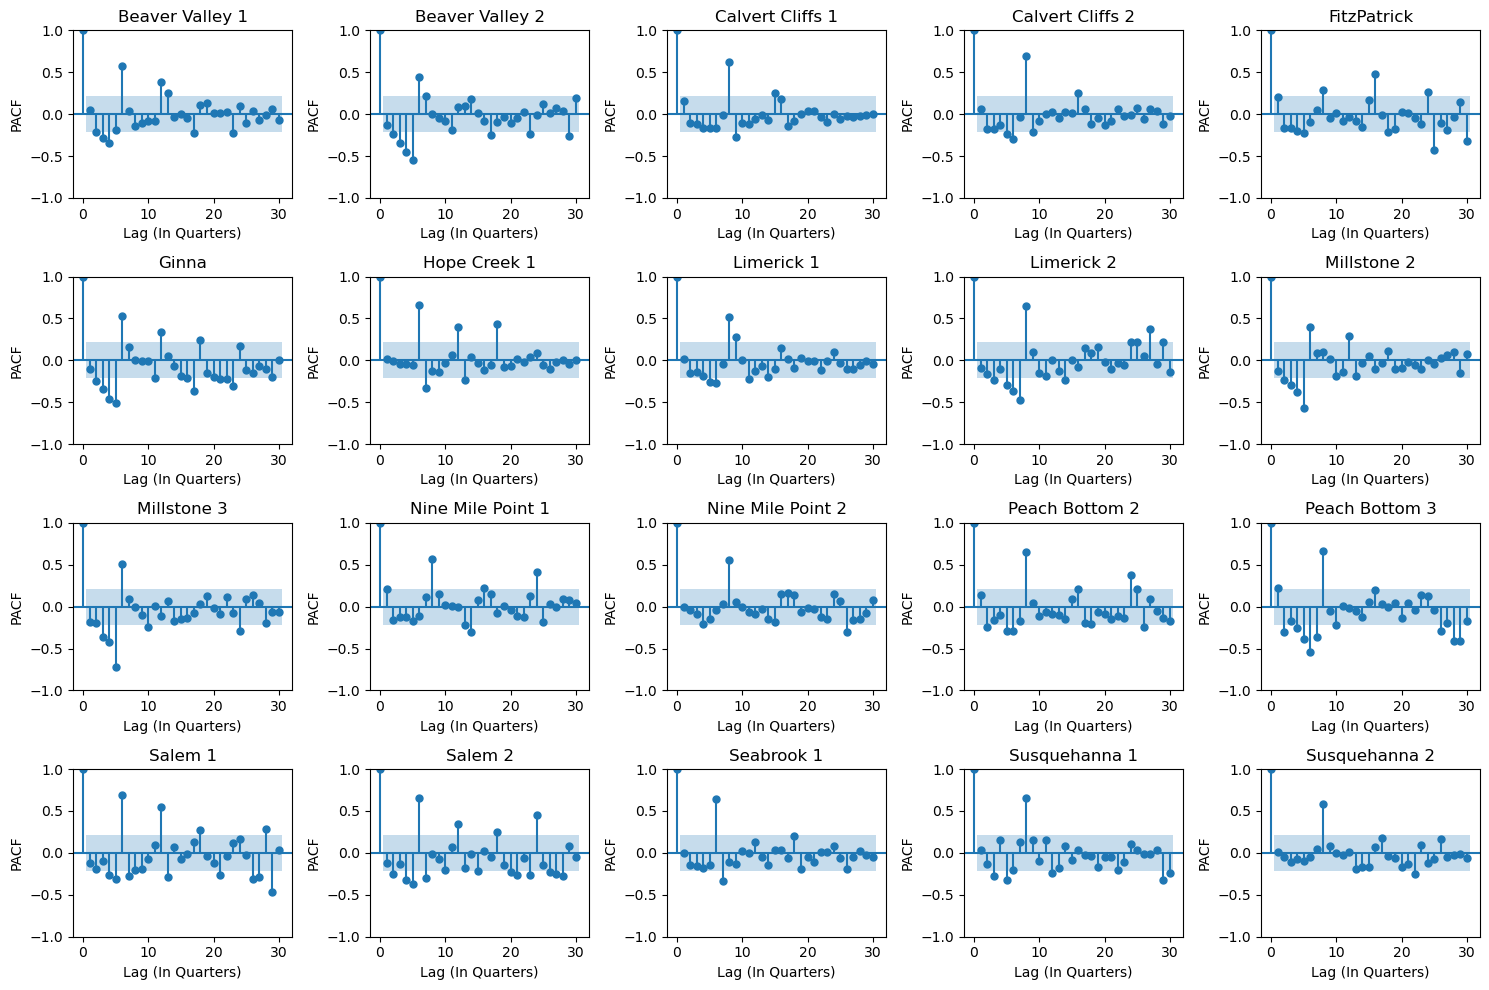

In [12]:
fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 10))
axes = axes.flatten()

for i in range(len(reactors)):  

    sm.graphics.tsa.plot_pacf(regional_df[ regional_df["Unit"] == reactors[i] ]["average_power"].reset_index(drop=True), lags=30, method = 'ols', ax=axes[i])

    axes[i].set_xlabel("Lag (In Quarters)")
    axes[i].set_ylabel("PACF")
    axes[i].set_title(f'{reactors[i]}')

plt.tight_layout()
plt.show()

Most reactors show clear ACF peaks at multiples of their cycle length, which confirms the seasonality, but the peaks are weak and fade quickly. This is consistent with cycles drifting by a few months over time, so outages do not line up exactly every 6 or 8 quarters. Short-lag correlations are small, so we expect low non-seasonal orders. Instead of choosing the orders by hand for 92 reactors, we let `auto_arima` search for them, using these plots as a sanity check.


In [13]:
from pmdarima import auto_arima, ARIMA

sarima_models = {}

for unit, unit_df in X_test.groupby("Unit"):

    if unit not in cycle_quarters:
        continue

    length = cycle_quarters[unit]

    y_train = X_train[X_train["Unit"] == unit]["average_power"].to_numpy()

    best = auto_arima(y_train, seasonal=True, m=length, error_action="ignore", d=0, D=1)
    model = ARIMA(order=best.order, seasonal_order=best.seasonal_order, with_intercept=False, suppress_warnings=True).fit(y_train)
    sarima_models[unit] = model

    # I am already passing a numpy array as an input so don't need to_numpy here.
    X_test.loc[ unit_df.index, "arima" ] = model.predict(n_periods=len(unit_df))
    X_train.loc[ X_train[X_train["Unit"] == unit].index, "arima_fit" ] = model.fittedvalues()

In [14]:
sarima = pd.DataFrame({unit : {"order": m.order, "seasonal_order": m.seasonal_order, "aic": m.aic()} for unit, m in sarima_models.items()}).T
sarima = sarima.reset_index()
sarima

,index,order,seasonal_order,aic
0,Arkansas Nuclear One 1,"(2, 0, 2)","(0, 1, 1, 6)",700.245241
1,Arkansas Nuclear One 2,"(0, 0, 0)","(0, 1, 1, 6)",660.8968
2,Beaver Valley 1,"(0, 0, 0)","(1, 1, 2, 6)",572.201343
3,Beaver Valley 2,"(0, 0, 1)","(0, 1, 1, 6)",543.12737
4,Braidwood 1,"(0, 0, 1)","(2, 1, 0, 6)",511.897677
...,...,...,...,...
87,Vogtle 2,"(0, 0, 0)","(0, 1, 2, 6)",563.756763
88,Waterford 3,"(0, 0, 0)","(0, 1, 1, 6)",651.119834
89,Watts Bar 1,"(0, 0, 0)","(2, 1, 0, 6)",611.031454
90,Watts Bar 2,"(0, 0, 0)","(1, 1, 0, 6)",111.614115


In [28]:
all_scores={}

for unit,unit_df in X_test.groupby("Unit"):

    # Vogtle 3 and 4 started late so there was nontraining date for them and thus no prediction either and ther corresponding cells are empty

    valid = unit_df[["seasonal_naive", "seasonal_average", "holt_winter", "arima"]].notna().all(axis=1)
    # valid would be a series of trueFalse for these 3 columsn and for empty cells it returns FALSE

    if valid.sum() == 0:
        continue

    naive = mae( unit_df.loc[valid, "average_power"], unit_df.loc[valid, "seasonal_naive"] )
    average = mae( unit_df.loc[valid, "average_power"], unit_df.loc[valid, "seasonal_average"] )
    holt = mae( unit_df.loc[valid, "average_power"], unit_df.loc[valid, "holt_winter"] )
    arima = mae( unit_df.loc[valid, "average_power"], unit_df.loc[valid, "arima"] )

    all_scores[unit] = { "Region": unit_df["Region"].iloc[0], "seasonal_naive": naive, "seasonal_average": average, "holt_winter":holt, "SARIMA":arima }

all_scores = pd.DataFrame(all_scores).T
all_scores = all_scores.reset_index()
all_scores = all_scores.rename(columns={"index": "Unit"})
all_scores

,Unit,Region,seasonal_naive,seasonal_average,holt_winter,SARIMA
0,Arkansas Nuclear One 1,Region 4,6.150404,8.032956,6.188124,8.670514
1,Arkansas Nuclear One 2,Region 4,12.934399,9.627172,10.304646,9.579357
2,Beaver Valley 1,Region 1,4.716537,4.066286,4.235575,5.696638
3,Beaver Valley 2,Region 1,2.815659,2.926987,3.199485,3.526729
4,Braidwood 1,Region 3,1.671197,1.068323,1.337947,1.078056
...,...,...,...,...,...,...
87,Vogtle 2,Region 2,2.335412,1.724151,2.663803,1.768894
88,Waterford 3,Region 4,15.51776,25.378643,26.413639,23.799598
89,Watts Bar 1,Region 2,19.511642,11.839663,13.760611,12.712015
90,Watts Bar 2,Region 2,12.240049,11.063094,12.441371,11.212212


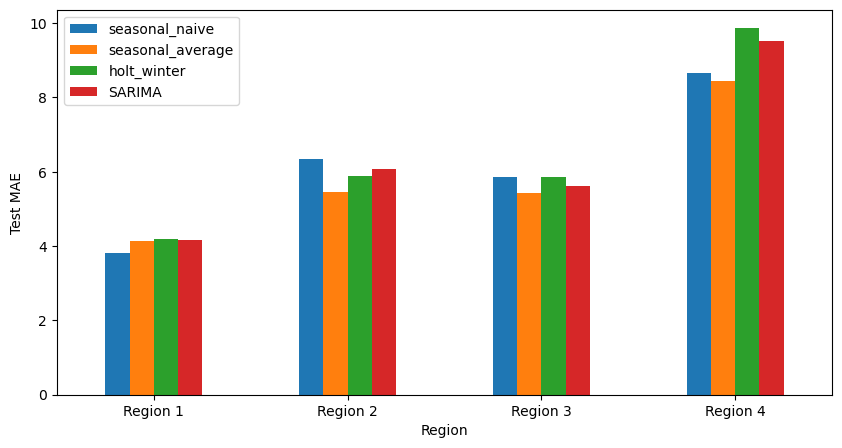

In [33]:
methods=["seasonal_naive", "seasonal_average", "holt_winter", "SARIMA"]
region_mean = all_scores.groupby("Region")[methods].mean()

region_mean.plot.bar(capsize=3, figsize=(10, 5))
plt.ylabel("Test MAE")
plt.xticks(rotation=0)
plt.show()

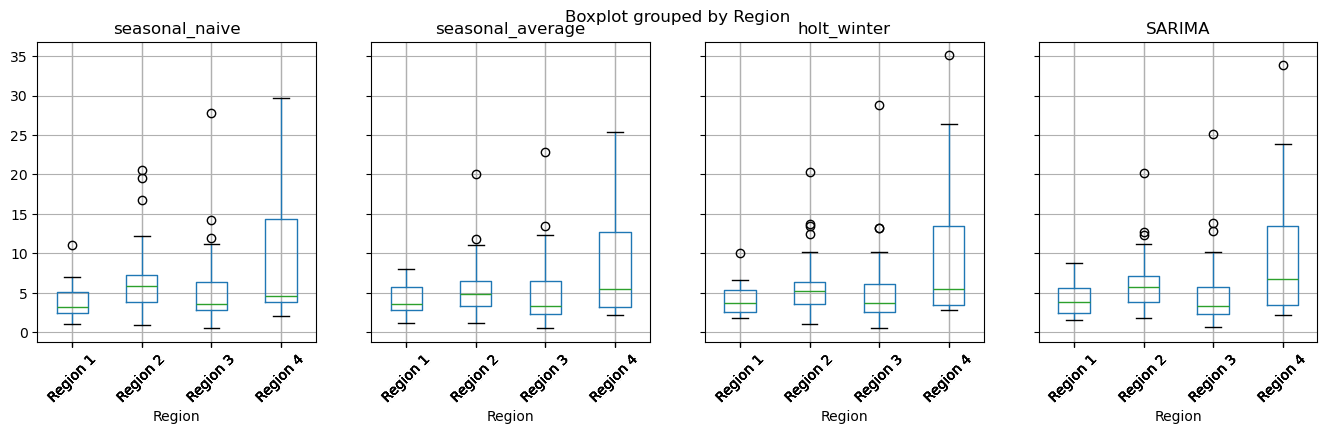

In [35]:
all_scores.boxplot(column=methods, by="Region", layout=(1, 4), figsize=(16, 4), rot=45, sharey=True)
plt.show()

### Reading the box plots

Each box summarises the test MAE of all reactors in one region for one method:

- **Green line:** the median reactor. Half the reactors have a lower MAE, half a higher one.
- **Box:** the middle 50% of reactors, from the 25th to the 75th percentile. Its height is the interquartile range (IQR); a taller box means the reactors differ more from each other.
- **Whiskers:** they extend to the most extreme reactor within 1.5 × IQR of the box. They are often unequal, which shows the errors are skewed.
- **Circles:** outliers beyond the whiskers. Each circle is a single reactor with an unusually large error.

The medians across all 4 regions are comparable but As can be seen from this plot many region 4 reactors have large errors.


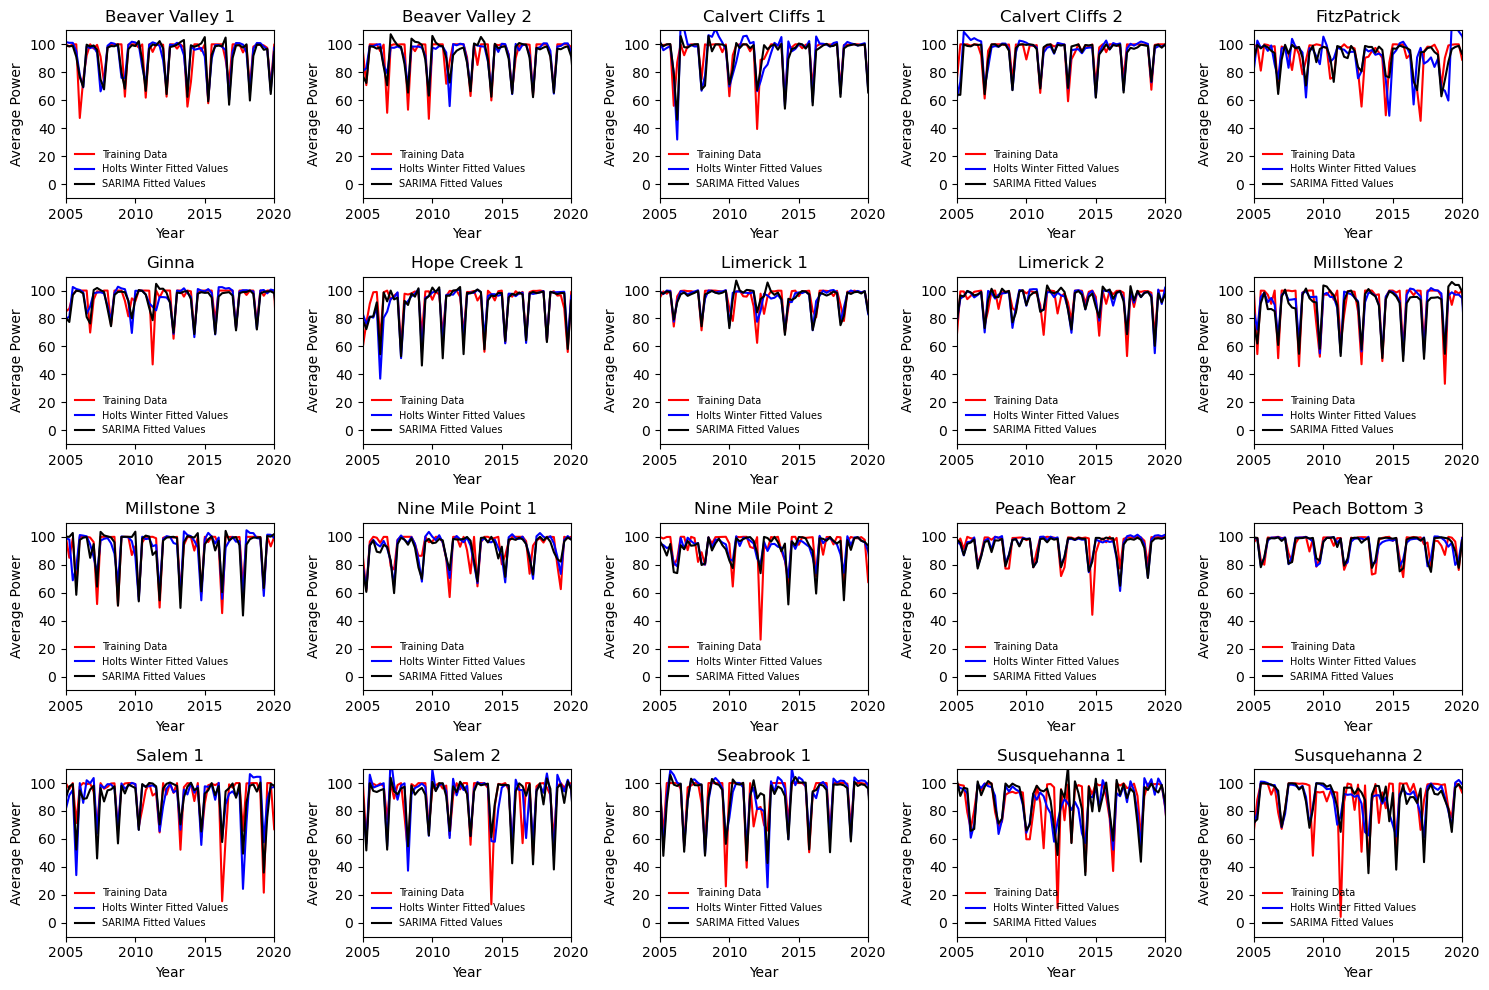

In [17]:
region = "Region 1"

regional_df = X_train[ X_train["Region"] == region ]
reactors = regional_df["Unit"].unique()

n_rows = 4
n_columns = math.ceil(len(reactors)/n_rows)

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 10))
axes = axes.flatten()

for i in range(len(reactors)):  

    axes[i].plot( regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["average_power"], color='red', label="Training Data" )

    axes[i].plot( regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["holt_winter_fit"], color='blue', label="Holts Winter Fitted Values" )

    axes[i].plot( regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["arima_fit"], color='black', label="SARIMA Fitted Values" )

    axes[i].legend(fontsize=7, frameon=False)
    axes[i].set_xlabel("Year")
    axes[i].set_ylabel("Average Power")
    axes[i].set_title(f'{reactors[i]}')
    axes[i].set_ylim(-10, 110)
    axes[i].set_xlim(pd.Timestamp("2005-01-01"), pd.Timestamp("2020-01-01"))
    axes[i].xaxis.set_major_locator(mdates.YearLocator(5))

plt.tight_layout()
plt.show()

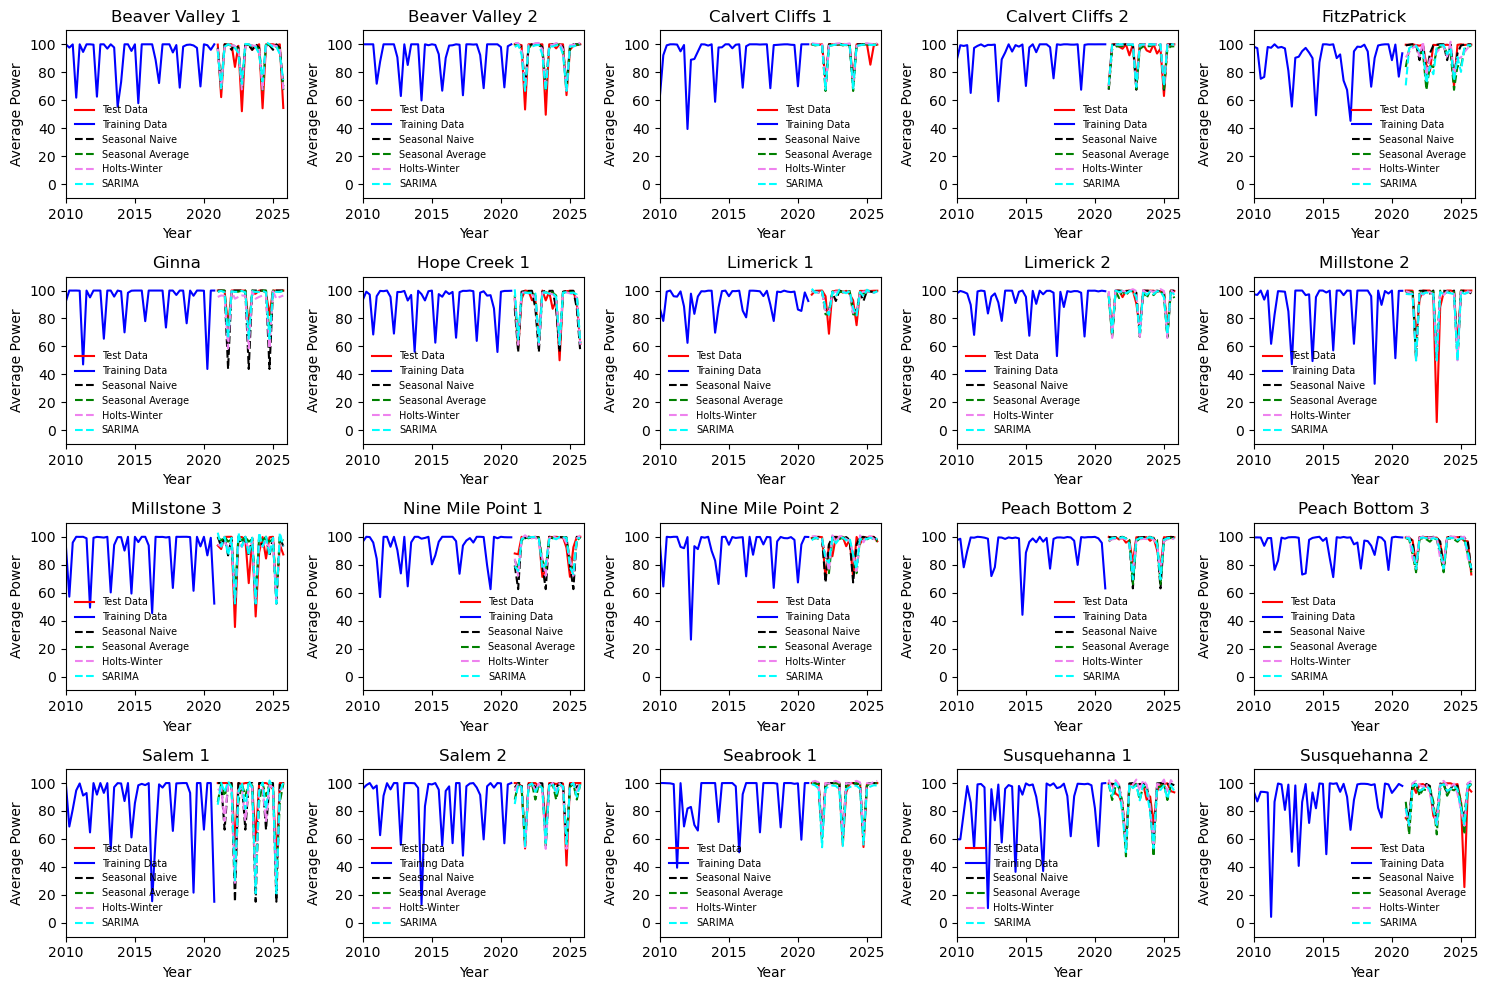

In [18]:
region = "Region 1"

regional_df = X_test[ X_test["Region"] == region ]
reactors = regional_df["Unit"].unique()

n_rows = 4
n_columns = math.ceil(len(reactors)/n_rows)

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 10))
axes = axes.flatten()

for i in range(len(reactors)):  

    axes[i].plot( regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["average_power"], color='red', label="Test Data" )

    axes[i].plot( X_train[ X_train["Unit"] == reactors[i] ]["quarter_start"], X_train[ X_train["Unit"] == reactors[i] ]["average_power"], color='blue', label='Training Data' )

    axes[i].plot( regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["seasonal_naive"], '--', color='black', label="Seasonal Naive" )

    axes[i].plot( regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["seasonal_average"], '--', color='green', label="Seasonal Average")

    axes[i].plot(regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["holt_winter"], '--', color='violet', label="Holts-Winter")

    axes[i].plot(regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["arima"], '--', color='cyan', label="SARIMA")


    axes[i].legend(fontsize=7, frameon=False)
    axes[i].set_xlabel("Year")
    axes[i].set_ylabel("Average Power")
    axes[i].set_title(f'{reactors[i]}')
    axes[i].set_ylim(-10, 110)
    axes[i].set_xlim(pd.Timestamp("2010-01-01"), pd.Timestamp("2026-01-01"))
    axes[i].xaxis.set_major_locator(mdates.YearLocator(5))

plt.tight_layout()
plt.show()